# Session 27 Solutions: Clustering with K-Means

Data Science with Python, Level 2, Stage 4: Applied ML

Try each exercise yourself before reading its solution. There is usually more than one correct answer; compare your approach with this one.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
DATA_URL = "https://raw.githubusercontent.com/mohammadyahoo/ds-python-course/main/data/"
mall = pd.read_csv(DATA_URL + "mall_customers.csv")

## In-Class Exercises

### In-Class Exercise 1: Three Segments

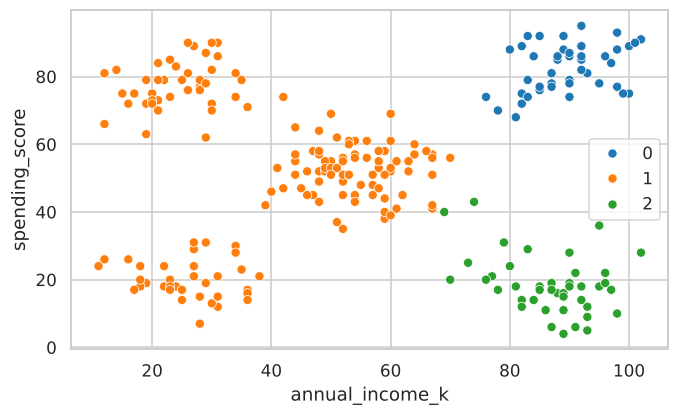

In [2]:
X = mall[["annual_income_k", "spending_score"]]
labels = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(X)
sns.scatterplot(data=mall, x="annual_income_k", y="spending_score", hue=labels, palette="tab10")
plt.show()

### In-Class Exercise 2: Gender by Segment

In [3]:
X = mall[["annual_income_k", "spending_score"]]
mall["segment"] = KMeans(n_clusters=5, n_init=10, random_state=0).fit_predict(X)
pd.crosstab(mall["segment"], mall["gender"], normalize="index").round(2)

gender,Female,Male
segment,,
0,0.60,0.40
1,0.52,0.48
2,0.42,0.58
3,0.51,0.49
4,0.42,0.57


### In-Class Exercise 3: Assign New Customers

In [4]:
X = mall[["annual_income_k", "spending_score"]]
kmeans = KMeans(n_clusters=5, n_init=10, random_state=0).fit(X)
new = pd.DataFrame({"annual_income_k": [30, 60, 95], "spending_score": [85, 50, 15]})
kmeans.predict(new)

array([2, 1, 4], dtype=int32)

### In-Class Exercise 4: Silhouette Chart

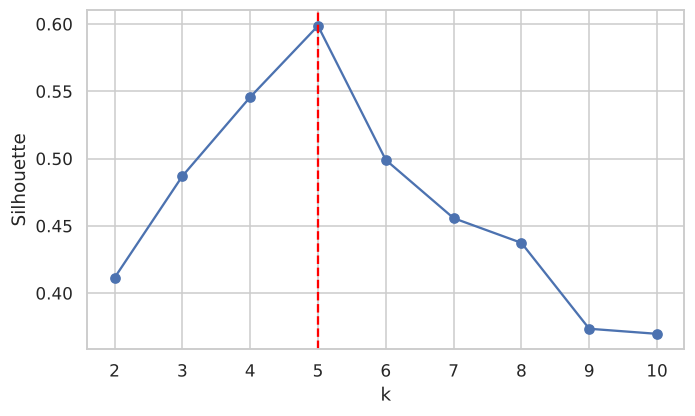

In [5]:
Xs = StandardScaler().fit_transform(mall[["age", "annual_income_k", "spending_score"]])
ks = range(2, 11)
sil = [silhouette_score(Xs, KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(Xs)) for k in ks]
plt.plot(ks, sil, marker="o")
plt.axvline(ks[int(np.argmax(sil))], color="red", linestyle="--")
plt.xlabel("k")
plt.ylabel("Silhouette")
plt.show()

## Part A: Basic

### Exercise 1: K-Means by Hand

In [6]:
pts = np.array([[1, 1], [1.5, 2], [3, 4], [5, 7], [3.5, 5], [4.5, 5], [3.5, 4.5]])
centres = pts[:2].astype(float)
for r in range(2):
    dist = np.linalg.norm(pts[:, None, :] - centres[None, :, :], axis=2)
    labels = dist.argmin(axis=1)
    centres = np.array([pts[labels == j].mean(axis=0) for j in range(2)])
    print("round", r + 1, labels, centres.round(2))

round 1 [0 1 1 1 1 1 1] [[1.   1.  ]
 [3.5  4.58]]
round 2 [0 0 1 1 1 1 1] [[1.25 1.5 ]
 [3.9  5.1 ]]


### Exercise 2: Visits and Spending

In [7]:
cols = ["visits_per_month", "spending_score"]
raw = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(mall[cols])
scaled = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(StandardScaler().fit_transform(mall[cols]))
print(mall.groupby(raw)[cols].mean().round(1))
print(mall.groupby(scaled)[cols].mean().round(1))

   visits_per_month  spending_score
0               6.7            80.5
1               3.4            18.7
2               5.0            52.1
   visits_per_month  spending_score
0               3.8            62.6
1               8.4            73.5
2               3.5            20.4


## Part B: Intermediate

### Exercise 3: Segmenting Apartments

In [8]:
flats = pd.read_csv(DATA_URL + "apartments.csv")
cols = ["area_m2", "building_age", "distance_center_km", "price_k"]
Xs = StandardScaler().fit_transform(flats[cols])
sil = {k: silhouette_score(Xs, KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(Xs)) for k in range(2, 9)}
best = max(sil, key=sil.get)
print({k: round(v, 3) for k, v in sil.items()}, "best", best)
flats["cluster"] = KMeans(n_clusters=best, n_init=10, random_state=0).fit_predict(Xs)
flats.groupby("cluster")[cols].mean().round(1).assign(n=flats["cluster"].value_counts())

{2: 0.257, 3: 0.241, 4: 0.26, 5: 0.263, 6: 0.257, 7: 0.257, 8: 0.259} best 5


,area_m2,building_age,distance_center_km,price_k,n
cluster,,,,,
0,83.5,7.7,6.3,82.4,188
1,79.7,29.8,2.5,94.1,168
2,128.6,27.8,7.3,101.5,148
3,119.4,15.8,2.6,158.7,150
4,75.1,32.0,7.2,60.4,146


### Exercise 4: Stable Clusters?

In [9]:
X = mall[["annual_income_k", "spending_score"]]
for n_init in [1, 10]:
    print(n_init, [round(KMeans(n_clusters=5, n_init=n_init, random_state=s).fit(X).inertia_) for s in range(5)])
# With one random start K-Means can get stuck in a poor solution; n_init keeps the best of several starts.

1 [24094, 24094, 24094, 24094, 24094]
10 [24094, 24094, 24094, 24094, 24094]


## Part C: Challenge

### Exercise 5: Cluster Customers of the Phone Company

Clustering ignores churn, but profiling the clusters with the churn rate turns segments into a practical call list.

In [10]:
tel = pd.read_csv(DATA_URL + "telecom_churn.csv")
cols = ["tenure_months", "monthly_charges", "support_calls"]
tel["cluster"] = KMeans(n_clusters=4, n_init=10, random_state=0).fit_predict(StandardScaler().fit_transform(tel[cols]))
tel["left"] = (tel["churn"] == "Yes").astype(int)
tel.groupby("cluster")[cols + ["left"]].mean().round(2).assign(n=tel["cluster"].value_counts())

,tenure_months,monthly_charges,support_calls,left,n
cluster,,,,,
0,57.46,68.83,1.19,0.06,349
1,20.91,77.93,0.50,0.37,713
2,22.59,74.77,2.67,0.46,494
3,23.74,35.18,1.14,0.22,444


## Part D: Cumulative Project: Customer Churn

### Exercise 6: Customer Churn: Step 4, Segments as a Feature

In [11]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
data = pd.read_csv(DATA_URL + "telecom_churn.csv")
y = (data["churn"] == "Yes").astype(int)
X = data.drop(columns=["customer_id", "churn"])
X_dev, X_final, y_dev, y_final = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
seg_cols = ["tenure_months", "monthly_charges", "support_calls"]
sc = StandardScaler().fit(X_dev[seg_cols])
km = KMeans(n_clusters=4, n_init=10, random_state=0).fit(sc.transform(X_dev[seg_cols]))
X_dev = X_dev.assign(segment=km.labels_.astype(str))
print(y_dev.groupby(X_dev["segment"]).mean().round(3))
num_cols = ["tenure_months", "monthly_charges", "total_charges", "support_calls"]
bool_cols = ["senior", "paperless_billing"]
def model(cat_cols):
    pre = ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
        ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="None"), OneHotEncoder(handle_unknown="ignore")), cat_cols),
        ("bool", "passthrough", bool_cols),
    ])
    return make_pipeline(pre, LogisticRegression(max_iter=1000))
base = ["gender", "contract", "internet", "payment_method"]
for name, cats in [("without segment", base), ("with segment", base + ["segment"])]:
    print(name, cross_val_score(model(cats), X_dev, y_dev, cv=5, scoring="roc_auc").mean().round(3))

segment
0    0.209
1    0.058
2    0.360
3    0.478
Name: churn, dtype: float64
without segment 0.786
with segment 0.785


## Part E: Quiz Answers

| Question | Answer | Explanation |
| --- | --- | --- |
| 1 | B | There is nothing to predict. |
| 2 | B | The centre is the cluster average. |
| 3 | B | Balance fit and simplicity. |
| 4 | B | Distances depend on units. |
| 5 | B | Labels are arbitrary. |